### Análise Exploratória (EDA)

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracao visual dos graficos

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [9]:
# Carregando o dataset tratado na Etapa 1

df = pd.read_csv('seoul_bike_tratado.csv')
df['date'] = pd.to_datetime(df['date'])
df['timestamp'] = pd.to_datetime(df['timestamp'])

df.head()

,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


In [10]:
# Para a analise exploratoria de demanda, o foco é nos dias em que o sistema funcionou

df_func = df[df['functioning_day'] == 'Yes']

print(f"Total de registros operacionais: {len(df_func)}")
df_func.head()

Total de registros operacionais: 8465


,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


/tmp/ipykernel_2747/1063233115.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_func, x='seasons', y='rented_bike_count', palette='Set2', ax=axes[1])


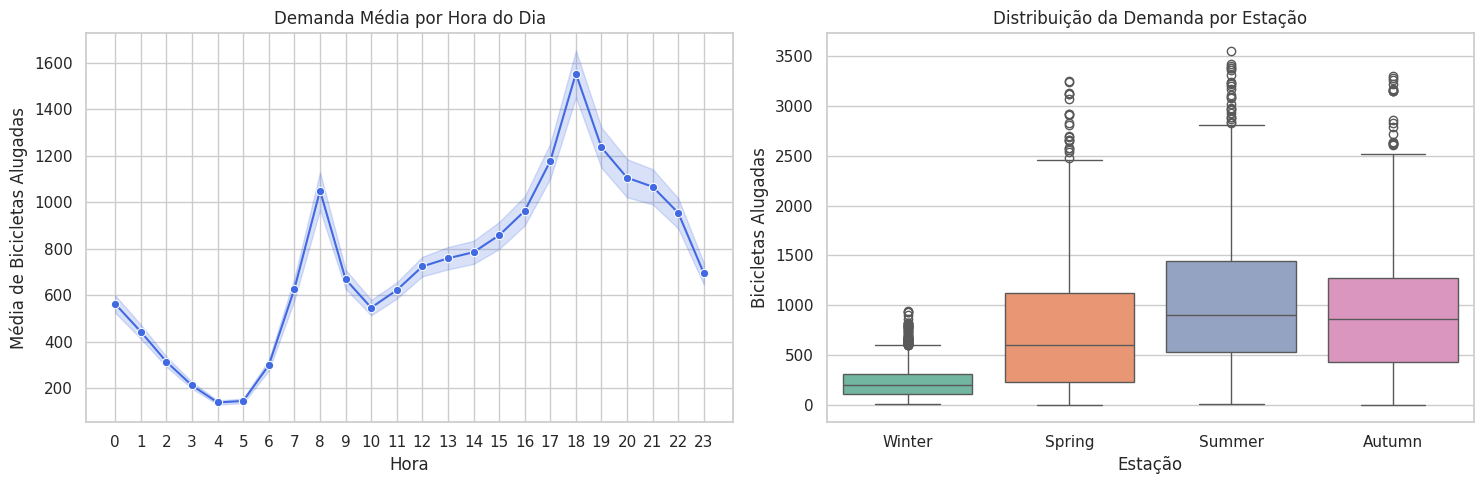

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Demanda media por hora do dia
sns.lineplot(data=df_func, x='hour', y='rented_bike_count', marker='o', color='royalblue', ax=axes[0])
axes[0].set_title('Demanda Média por Hora do Dia')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Média de Bicicletas Alugadas')
axes[0].set_xticks(range(0, 24))

# Distribuicao da demanda por estação
sns.boxplot(data=df_func, x='seasons', y='rented_bike_count', palette='Set2', ax=axes[1])
axes[1].set_title('Distribuição da Demanda por Estação')
axes[1].set_xlabel('Estação')
axes[1].set_ylabel('Bicicletas Alugadas')

plt.tight_layout()
plt.show()

In [12]:
# Medidas numericas por estacao para confirmar a variabilidade
df_func.groupby('seasons')['rented_bike_count'].agg(['mean', 'median', 'std', 'min', 'max'])

,mean,median,std,min,max
seasons,,,,,
Autumn,924.110480,856.0,617.547879,2,3298
Spring,746.254167,599.0,618.667962,2,3251
Summer,1034.073370,905.5,690.244759,9,3556
Winter,225.541204,203.0,150.372236,3,937


O primeiro gráfico responde a pergunta:  Quais horários têm maior demanda? <p>

O gráfico tem 2 picos um na parte da manhã às 8h (média de quase 1.000 bikes) e outro pico na parte da tarde entre 17h e 19h (com top às 18h). Isso pode significar que as bikes são utilizadas para transporte de trabalho/estudo e não só para lazer

O segundo gráfico e tabela respondem a pergunta: Qual estação do ano tem maior média e qual tem maior variabilidade? <p>

Pela tabela conseguimos ver que no Verão apresenta uma maior média no aluguel das bicicletas, e pelo boxplot conseguimos ver que no verão também temos uma maior variabilidade tanto pelo tamanho da sua caixa quanto o tamanho da sua hastes, que representam maior espalhamento dos dados. Destaque também para o inverno que tem a menor média (225) e menor desvio padrão (150) devido ao frio intenso.

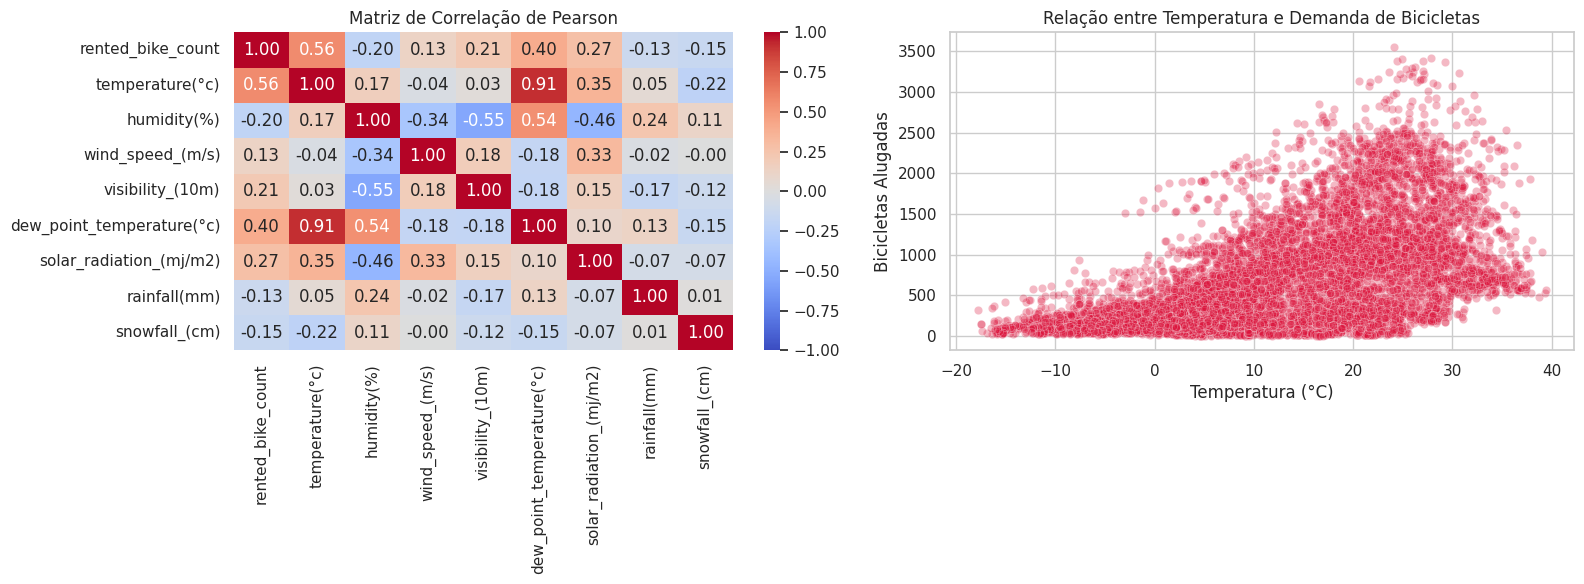

rented_bike_count            1.000000
temperature(°c)              0.562740
dew_point_temperature(°c)    0.400263
solar_radiation_(mj/m2)      0.273862
visibility_(10m)             0.212323
wind_speed_(m/s)             0.125022
rainfall(mm)                -0.128626
snowfall_(cm)               -0.151611
humidity(%)                 -0.201973
Name: rented_bike_count, dtype: float64

In [13]:
# Selecionando apenas variaveis numericas relevantes para correlacao
colunas_num = [
    'rented_bike_count', 'temperature(°c)', 'humidity(%)', 
    'wind_speed_(m/s)', 'visibility_(10m)', 'dew_point_temperature(°c)',
    'solar_radiation_(mj/m2)', 'rainfall(mm)', 'snowfall_(cm)'
]

corr = df_func[colunas_num].corr()

# Plotando o Mapa de Calor (Heatmap) e a Dispersao com Temperatura
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap de correlacao
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Matriz de Correlação de Pearson')

# Dispersao: Temperatura vs Aluguel de Bicicletas
sns.scatterplot(data=df_func, x='temperature(°c)', y='rented_bike_count', alpha=0.3, color='crimson', ax=axes[1])
axes[1].set_title('Relação entre Temperatura e Demanda de Bicicletas')
axes[1].set_xlabel('Temperatura (°C)')
axes[1].set_ylabel('Bicicletas Alugadas')

plt.tight_layout()
plt.show()

# Verificando as correlacoes diretas com a variavel alvo ordenada
corr['rented_bike_count'].sort_values(ascending=False)

Analisando as correlações entre as variáveis numéricas observa-se que temperatura e ponto de orvalho possuem uma correlação (0.91) muito grande positivamente, ou seja, elas acabam entregando quase a mesma informação. Enquanto umidade e visibilidade possuem a menor correlação entre as variáveis numéricas indicando que quanto mais umidade, seja em chuva ou neblina, menor é visibilidade. <p>

No gráfico de dispersão é possível analisar que quanto mais quente está mais as pessoas tendem a alugar bikes, tendo um pico então entre aproximadamente 20º e 28º depois disso começa a diminuir mostrando que muito quente também desistimula as pessoas a andarem de bike.

/tmp/ipykernel_2747/4279840976.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_func, x='holiday', y='rented_bike_count', palette='Pastel1', ax=axes[0])


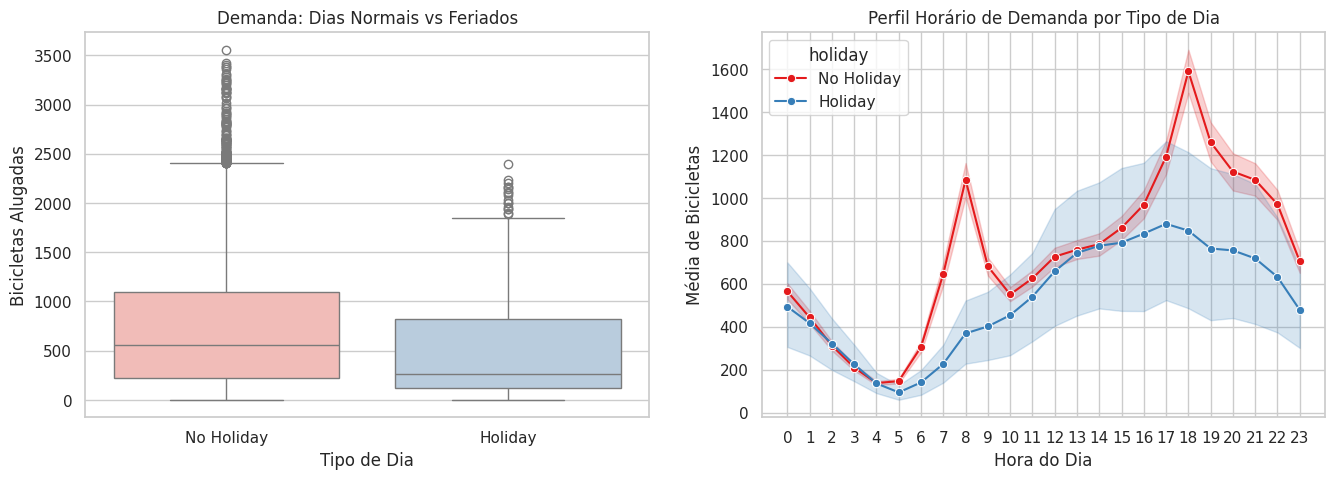

,count,mean,median,std
holiday,,,,
Holiday,408,529.154412,259.0,573.932260
No Holiday,8057,739.284970,561.0,644.004661


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Comparacao da distribuicao geral: Feriado vs Dia Normal
sns.boxplot(data=df_func, x='holiday', y='rented_bike_count', palette='Pastel1', ax=axes[0])
axes[0].set_title('Demanda: Dias Normais vs Feriados')
axes[0].set_xlabel('Tipo de Dia')
axes[0].set_ylabel('Bicicletas Alugadas')

# Curva horaria comparando Feriado vs Dia Normal
sns.lineplot(data=df_func, x='hour', y='rented_bike_count', hue='holiday', marker='o', palette='Set1', ax=axes[1])
axes[1].set_title('Perfil Horário de Demanda por Tipo de Dia')
axes[1].set_xlabel('Hora do Dia')
axes[1].set_ylabel('Média de Bicicletas')
axes[1].set_xticks(range(0, 24))

plt.show()

# Medidas estatisticas
df_func.groupby('holiday')['rented_bike_count'].agg(['count', 'mean', 'median', 'std'])

Com este boxplot é possível notar que em um dia comum a quantidade de bicicletas alugadas por hora é muito superior à de um feriado e também é possível ver que nos dias normais há mais variabilidade nos dados. <p>

O segundo gráfico mostrauma comparação dos alugueis de bikes em relação as horas do dia, como nos feriados não possuem casos de picos muito elevados como nos dias normais tendo sim uma tendência de aumento ali pela parte da tarde até as 17h mas a partir disso começa a diminuir. <p>

Esses gráficos provam que em dias normais com as demandas de trabalho, estudo, lazer misturado entre outras tendem a ter um número maior de bikes alugadas do que nos dias de feriado.

### Resumo da análise exploratória

Primeiro foram separados somente os 8.465 registros para análise nos quais tiveram dias funcionais. <p>

Foi possível constatar que nos dias normais, ou seja, que não são feriados há uma maior tendência as pessoas alugarem bikes com destaque para os horários das 17h às 19h que representam o maior pico e com um outro pico no horário das 8h, muito possivelmente representando as pessoas que estão indo e voltando do trabalho/estudo. <p>

Também foi possível constatar que as pessoas tendem a alugar mais bikes no verão comprovado em outras análises onde mostraram que quanto maior a temperatura mais as pessoas alugaram até certo ponto de aproximadamente 30º. E sobre correlação foi verificado que temperatura e ponto de orvalho apresentam uma correlação muito próxima positivamente que oferecem quase o mesmo dado e que umidade e visibilidade possuem a maior correlação negativa, ou seja, quanto mais umidade menor é a visibilidade, seja pela chuva, neblina, neve dentre outros.